# Plotting time evolution of mean parameter at each shock

We just compare on the outer shock and compare two parameters against each other, since otherwise it gets too boring in one plot.

We also plot the pressure time series, comparing CR pressure and thermal pressure

In [2]:
import numpy as np
import os
import astropy.units as u
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.ticker as ticker

import h5py
import json

from field_config import field_labels, field_lims, field_scales

In [3]:
bowshock_config_dict = json.load(open("../config/bowshock_config.json"))
bowshock_config = bowshock_config_dict["config"]
shock_labels = bowshock_config_dict["shock_labels"]

fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crmhd_vs_mhd"

In [1]:
shck_idx = 0  # 0 for outer, 1 for termination

fig, ax = plt.subplots(figsize=(8,6))
# ax_mag = ax.twinx()  # axes for magnetic field
# ax_vel = ax.twinx()  # axes for velocity field

pf = h5py.File(f"../data/time_evo.h5", "r")

sim_handles = []

for sim in list(bowshock_config.keys()):
    times = pf[sim]["times"][()]
    dens_data = pf[sim]["dens"][()]
    mag_data = pf[sim]["mag"][()]
    
    # sorting based on increasing time
    dens_data = dens_data[np.argsort(times), :]
    mag_data = mag_data[np.argsort(times), :]
    times = np.sort(times)

    # plotting density based on line style
    ax.plot(times, dens_data[:,shck_idx], ls="-", color=bowshock_config[sim]["color"], lw=3.0)

    # plotting magnetic field based on linestyle
    # ax_mag.plot(times, mag_data[:,shck_idx], ls="--", color=bowshock_config[sim]["color"], lw=3.0)
    
    sim_handles.append(
            mlines.Line2D(
                [0], [0], lw=3.0, color=bowshock_config[sim]["color"], label=bowshock_config[sim]["label"]
            )
        )


ax.set_xlabel("Time / kyr", fontsize=18)
ax.set_xlim(0, 200)

# setting indivudial ylim and ysccale
ax.set_ylim(3e-25, 13e-25)
ax.set_yscale("linear")
ax.set_ylabel(r"$\langle \rho \rangle$ / g cm$^{-3}$", fontsize=18)
# Use ScalarFormatter for better scientific notation
ax.ticklabel_format(useMathText=True)
ax.yaxis.get_offset_text().set_size(18)
# ax_mag.set_ylim(9e-7, 4e-5)
# ax_mag.set_yscale(field_scales["mag"])
# ax_mag.set_ylabel(r"$\langle |\vec{B}| \rangle$ / G", fontsize=18)

ax.tick_params(
                axis="both",
                direction="in",
                which="major",
                size=8,
                labelsize=18,
            )
ax.tick_params(
                axis="both",
                direction="in",
                which="minor",
                size=6,
                labelsize=16,
            )

leg1 = fig.legend(handles=sim_handles[:2], prop={"size":17}, bbox_to_anchor=[0.5,0.875], ncol=1, framealpha=0.0)
fig.add_artist(leg1)
leg2 = fig.legend(handles=sim_handles[2:], prop={"size":18}, bbox_to_anchor=[0.88,0.88], ncol=1, framealpha=0.0)

pf.close()

fig.savefig(f"{fig_dir}/dens_time_evo.pdf", dpi=200, bbox_inches="tight")

NameError: name 'plt' is not defined

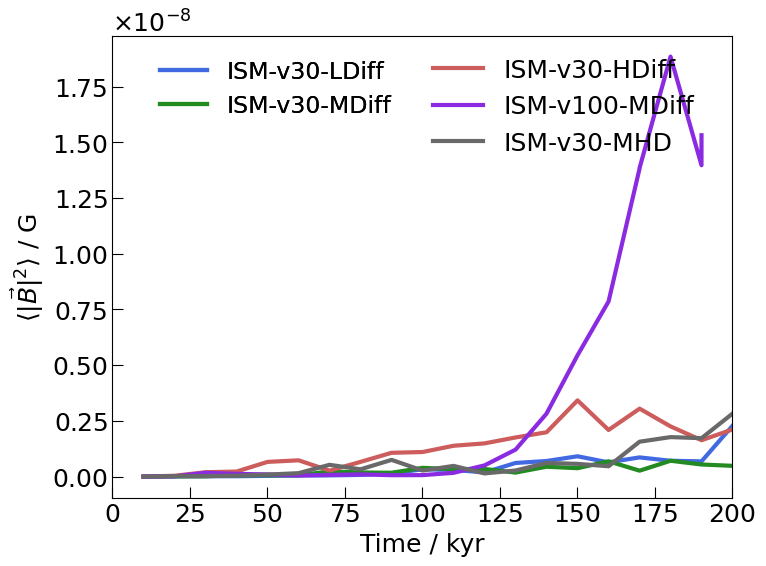

In [26]:
shck_idx = 0  # 0 for outer, 1 for termination

fig, ax = plt.subplots(figsize=(8,6))
# ax_mag = ax.twinx()  # axes for magnetic field
# ax_vel = ax.twinx()  # axes for velocity field

pf = h5py.File(f"../data/time_evo.h5", "r")

sim_handles = []

for sim in list(bowshock_config.keys()):
    times = pf[sim]["times"][()]
    mag_data = pf[sim]["mag"][()]
    
    # sorting based on increasing time
    mag_data = mag_data[np.argsort(times), :]
    times = np.sort(times)

    # plotting density based on line style
    ax.plot(times, mag_data[:,shck_idx], ls="-", color=bowshock_config[sim]["color"], lw=3.0)

    # plotting magnetic field based on linestyle
    # ax_mag.plot(times, mag_data[:,shck_idx], ls="--", color=bowshock_config[sim]["color"], lw=3.0)
    
    sim_handles.append(
            mlines.Line2D(
                [0], [0], lw=3.0, color=bowshock_config[sim]["color"], label=bowshock_config[sim]["label"]
            )
        )


ax.set_xlabel("Time / kyr", fontsize=18)
ax.set_xlim(0, 200)

# setting indivudial ylim and ysccale
# ax.set_ylim(3e-25, 13e-25)
# ax.set_yscale("linear")
ax.set_ylabel(r"$\langle | \vec{B} |^2 \rangle$ / G", fontsize=18)
# Use ScalarFormatter for better scientific notation
ax.set_ylim(1e-6, 8e-6)
ax.set_yscale("linear")
ax.ticklabel_format(useMathText=True)
ax.yaxis.get_offset_text().set_size(18)
# ax_mag.set_yscale(field_scales["mag"])
# ax_mag.set_ylabel(r"$\langle |\vec{B}| \rangle$ / G", fontsize=18)

ax.tick_params(
                axis="both",
                direction="in",
                which="major",
                size=8,
                labelsize=18,
            )
ax.tick_params(
                axis="both",
                direction="in",
                which="minor",
                size=6,
                labelsize=16,
            )

leg1 = fig.legend(handles=sim_handles[:2], prop={"size":17}, bbox_to_anchor=[0.5,0.875], ncol=1, framealpha=0.0)
fig.add_artist(leg1)
leg2 = fig.legend(handles=sim_handles[2:], prop={"size":18}, bbox_to_anchor=[0.88,0.88], ncol=1, framealpha=0.0)

pf.close()

# fig.savefig(f"{fig_dir}/mag_time_evo.pdf", dpi=200, bbox_inches="tight")

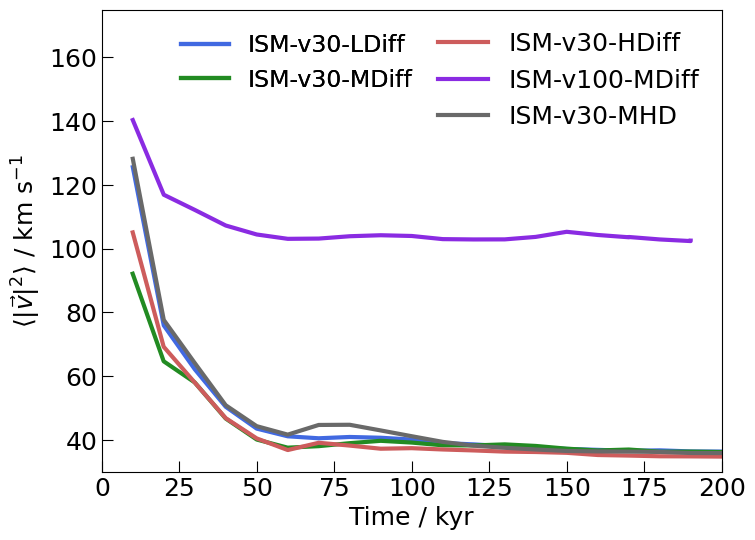

In [33]:
shck_idx = 0  # 0 for outer, 1 for termination

fig, ax = plt.subplots(figsize=(8,6))
# ax_mag = ax.twinx()  # axes for magnetic field
# ax_vel = ax.twinx()  # axes for velocity field

pf = h5py.File(f"../data/time_evo.h5", "r")

sim_handles = []

for sim in list(bowshock_config.keys()):
    times = pf[sim]["times"][()]
    vel_data = pf[sim]["vel"][()]
    
    # sorting based on increasing time
    vel_data = vel_data[np.argsort(times), :]
    times = np.sort(times)

    # plotting density based on line style
    ax.plot(times, vel_data[:,shck_idx], ls="-", color=bowshock_config[sim]["color"], lw=3.0)

    # plotting magnetic field based on linestyle
    # ax_mag.plot(times, mag_data[:,shck_idx], ls="--", color=bowshock_config[sim]["color"], lw=3.0)
    
    sim_handles.append(
            mlines.Line2D(
                [0], [0], lw=3.0, color=bowshock_config[sim]["color"], label=bowshock_config[sim]["label"]
            )
        )


ax.set_xlabel("Time / kyr", fontsize=18)
ax.set_xlim(0, 200)

# setting indivudial ylim and ysccale
# ax.set_ylim(3e-25, 13e-25)
# ax.set_yscale("linear")
ax.set_ylabel(r"$\langle | \vec{v} |^2 \rangle$ / km s$^{-1}$", fontsize=18)
# Use ScalarFormatter for better scientific notation
ax.set_ylim(30, 175)
ax.set_yscale("linear")
ax.ticklabel_format(useMathText=True)
ax.yaxis.get_offset_text().set_size(18)
# ax_mag.set_yscale(field_scales["mag"])
# ax_mag.set_ylabel(r"$\langle |\vec{B}| \rangle$ / G", fontsize=18)

ax.tick_params(
                axis="both",
                direction="in",
                which="major",
                size=8,
                labelsize=18,
            )
ax.tick_params(
                axis="both",
                direction="in",
                which="minor",
                size=6,
                labelsize=16,
            )

leg1 = fig.legend(handles=sim_handles[:2], prop={"size":17}, bbox_to_anchor=[0.54,0.875], ncol=1, framealpha=0.0)
fig.add_artist(leg1)
leg2 = fig.legend(handles=sim_handles[2:], prop={"size":18}, bbox_to_anchor=[0.9,0.88], ncol=1, framealpha=0.0)

pf.close()

fig.savefig(f"{fig_dir}/vel_time_evo.pdf", dpi=200, bbox_inches="tight")

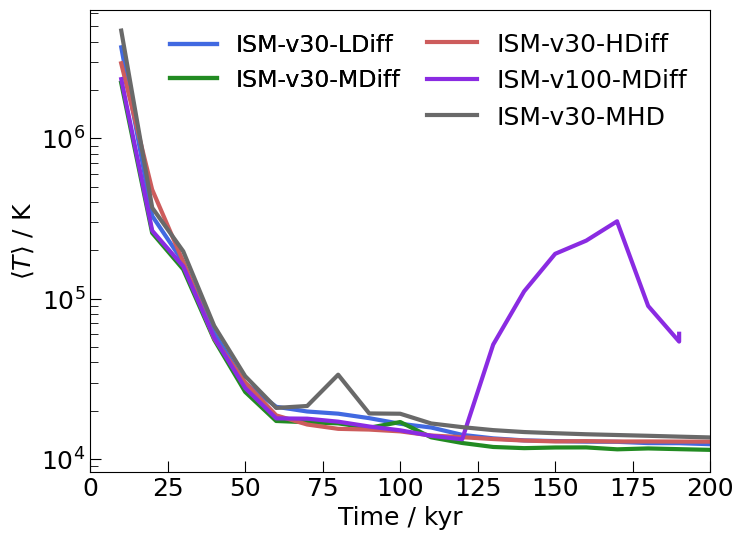

In [40]:
shck_idx = 0  # 0 for outer, 1 for termination

fig, ax = plt.subplots(figsize=(8,6))
# ax_mag = ax.twinx()  # axes for magnetic field
# ax_vel = ax.twinx()  # axes for velocity field

pf = h5py.File(f"../data/time_evo.h5", "r")

sim_handles = []

for sim in list(bowshock_config.keys()):
    times = pf[sim]["times"][()]
    temp_data = pf[sim]["temp"][()]
    
    # sorting based on increasing time
    temp_data = temp_data[np.argsort(times), :]
    times = np.sort(times)

    # plotting density based on line style
    ax.plot(times, temp_data[:,shck_idx], ls="-", color=bowshock_config[sim]["color"], lw=3.0)

    # plotting magnetic field based on linestyle
    # ax_mag.plot(times, mag_data[:,shck_idx], ls="--", color=bowshock_config[sim]["color"], lw=3.0)
    
    sim_handles.append(
            mlines.Line2D(
                [0], [0], lw=3.0, color=bowshock_config[sim]["color"], label=bowshock_config[sim]["label"]
            )
        )


ax.set_xlabel("Time / kyr", fontsize=18)
ax.set_xlim(0, 200)

# setting indivudial ylim and ysccale
# ax.set_ylim(3e-25, 13e-25)
# ax.set_yscale("linear")
ax.set_ylabel(r"$\langle T \rangle$ / K", fontsize=18)
# Use ScalarFormatter for better scientific notation
# ax.set_ylim(30, 175)
ax.set_yscale("log")
# ax.ticklabel_format(useMathText=True)
# ax.yaxis.get_offset_text().set_size(18)
# ax_mag.set_yscale(field_scales["mag"])
# ax_mag.set_ylabel(r"$\langle |\vec{B}| \rangle$ / G", fontsize=18)

ax.tick_params(
                axis="both",
                direction="in",
                which="major",
                size=8,
                labelsize=18,
            )
ax.tick_params(
                axis="both",
                direction="in",
                which="minor",
                size=6,
                labelsize=16,
            )

leg1 = fig.legend(handles=sim_handles[:2], prop={"size":17}, bbox_to_anchor=[0.54,0.875], ncol=1, framealpha=0.0)
fig.add_artist(leg1)
leg2 = fig.legend(handles=sim_handles[2:], prop={"size":18}, bbox_to_anchor=[0.9,0.88], ncol=1, framealpha=0.0)

pf.close()

# fig.savefig(f"{fig_dir}/temp_time_evo.pdf", dpi=200, bbox_inches="tight")

### Now plotting pressure instead

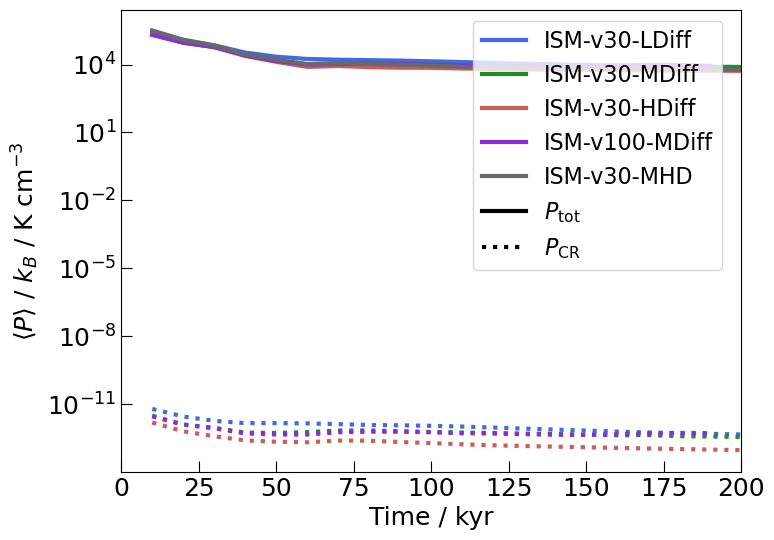

In [38]:
shck_idx = 0  # 0 for outer, 1 for termination


fig, ax = plt.subplots(figsize=(8,6))
# ax_vel = ax_dens.twinx()  # axes for velocity field

pf = h5py.File(f"../data/time_evo.h5", "r")

sim_handles = []

for sim in list(bowshock_config.keys()):
    times = pf[sim]["times"][()]
    pres_data = pf[sim]["pres"][()]
    pth_data = pf[sim]["pth"][()]

    
    zorder = 20 if sim == "ISM-v30-MHD" else 5
    alpha=1.0 if sim == "ISM-v30-MHD" else 1.0
    c = "k" if sim == "ISM-v30-MHD" else bowshock_config[sim]["color"]

    ax.plot(np.sort(times), pres_data[np.argsort(times),shck_idx], ls="-", color=bowshock_config[sim]["color"], lw=3.0, alpha=alpha, zorder=zorder)
    ax.plot(np.sort(times), pth_data[np.argsort(times),shck_idx], ls=":", color=bowshock_config[sim]["color"], lw=3.0, alpha=alpha, zorder=zorder)

    # if sim == "ISM-v30":
    #     ax.plot(times, pf[sim]["prcr"][()][np.argsort(times),shck_idx], ls=":", color=bowshock_config[sim]["color"], lw=3.0)
    
    sim_handles.append(
            mlines.Line2D(
                [0], [0], lw=3.0, color=bowshock_config[sim]["color"], label=bowshock_config[sim]["label"]
            )
        )


ax.set_xlabel("Time / kyr", fontsize=18)
ax.set_xlim(0, 200)

# setting indivudial ylim and ysccale
ax.set_ylim(3e3, 5e5)
ax.set_yscale(field_scales["pres"])
ax.set_ylabel(r"$\langle P \rangle$ / $k_B$ / K cm$^{-3}$", fontsize=18)
ax.tick_params(
                axis="both",
                direction="in",
                which="major",
                size=8,
                labelsize=18,
            )
ax.tick_params(
                axis="both",
                direction="in",
                which="minor",
                size=6,
                labelsize=16,
            )

handles = [*sim_handles, mlines.Line2D(
                [0], [0], lw=3.0, color="k", label="$P_\mathrm{tot}$", ls="-"
            ),
            mlines.Line2D(
                [0], [0], lw=3.0, color="k", label="$P_\mathrm{th}$", ls=":"
            ),
            # mlines.Line2D(
            #     [0], [0], lw=2.0, color="k", label="$P_\mathrm{CR}$", ls=":"
            # )
        ]

fig.legend(handles=handles, prop={"size":16}, bbox_to_anchor=[0.89,0.88])

pf.close()

fig.savefig(f"{fig_dir}/pres_time_evo.pdf", dpi=200, bbox_inches="tight")